In [1]:
%load_ext autoreload
%autoreload 2

# TP Arbres de Decision

#### 0. Chargement des données avec `load_data`

In [2]:
import TP1.data_arbres as da

data = da.load_data("tp_donnees.csv")
print("Il y a {nb} éléments dans le dataset".format(nb=len(data)))
print("Les attributs sont : {att}".format(att=data[0].x.keys()))
print("Les classes sont : {classes}".format(classes=set([d.y for d in data])))
print("Exemple de données : {data}".format(data=data[0]))

Il y a 1045 éléments dans le dataset
Les attributs sont : dict_keys(['Classe', 'Nationalite', 'Age', 'Nombre de freres/soeurs', 'Nombre d enfants/parents a bord', 'Prix du ticket', 'Genre'])
Les classes sont : {0, 1}
Exemple de données : x: {'Classe': 3.0, 'Nationalite': 0.0, 'Age': 42.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 7.55, 'Genre': 0.0}, y: 0


#### 1. Creez une fonction `proba_empirique`, prenant *d* une liste de DataPoint, et renvoyant la liste des *p_i*, où *p_i* est la proportion d’éléments de *d* de classe *i*.

In [3]:
proportion = da.proba_empirique(data)

for key in proportion.keys():
    print("La classe {key} a une proportion de {p}".format(key=key, p=proportion.get(key)))

La classe 0 a une proportion de 0.5913875598086125
La classe 1 a une proportion de 0.40861244019138754


#### 2. Creez une fonction `question_inf`, prenant un *x* de DataPoint, le nom d’un attribut *a* et une valeur *s*, et renvoyant vrai si *x[a] < s*, faux sinon.

In [4]:
x = data[0].x
print("Age = {a}".format(a=x["Age"]))
print("Age < {s} : {v}".format(s=x["Age"], v=da.question_inf(x, "Age", x["Age"])))
print("Age < {s} : {v}".format(s=x["Age"] + 1, v=da.question_inf(x, "Age", s=x["Age"] + 1)))

Age = 42.0
Age < 42.0 : False
Age < 43.0 : True


#### 3. Ajoutez une fonction `split`, prenant une liste de DataPoint *d*, le nom d’un attribut *a* et une valeur *s*, et renvoyant deux listes *d_1* et *d_2* correspondant à la partition de *d* suivant la question (*a, s*).

In [5]:
d1, d2 = da.split(data, "Genre", 0.5)
print("d1 contient {nb} éléments".format(nb=len(d1)))
print("d2 contient {nb} éléments".format(nb=len(d2)))

d1 contient 657 éléments
d2 contient 388 éléments


#### 4. Ajoutez une fonction `list_separ_attributs`, prenant une liste de DataPoint *d* et un nom d’attribut *a*, et renvoyant une liste de questions de type (*a, s*) pour tous les *s* pertinents.

In [6]:
x = da.list_separ_attributs(data, "Classe")
print("Les valeurs pertinentes pour l'attribut Classe sont : {x}".format(x=x))

Les valeurs pertinentes pour l'attribut Classe sont : [1.5, 2.5]


#### 5. Déduisez en la fonction `liste_questions`, qui étant donnée une liste de DataPoint *d*, renvoie la liste des questions pertinentes de forme (*a, s*) à poser sur les éléments de *d*.

In [7]:
questions = da.liste_questions(data)
for key in questions.keys():
    print("Il y a {nb} questions pertinentes pour l'attribut {key}".format(nb=len(questions.get(key)), key=key))

Il y a 2 questions pertinentes pour l'attribut Classe
Il y a 2 questions pertinentes pour l'attribut Nationalite
Il y a 96 questions pertinentes pour l'attribut Age
Il y a 6 questions pertinentes pour l'attribut Nombre de freres/soeurs
Il y a 6 questions pertinentes pour l'attribut Nombre d enfants/parents a bord
Il y a 255 questions pertinentes pour l'attribut Prix du ticket
Il y a 1 questions pertinentes pour l'attribut Genre


#### 6. Créez une fonction `entropie`, prenant une liste de DataPoint et renvoyant l’entropie de cette liste.

In [8]:
print("L'entropie de la liste est de {h}".format(h=da.entropie(data)))
print("L'entropie de la sous liste d1 est de {h}".format(h=da.entropie(d1)))
print("L'entropie de la sous liste d2 est de {h}".format(h=da.entropie(d2)))

L'entropie de la liste est de 0.9757661302191036
L'entropie de la sous liste d1 est de 0.7327525499549905
L'entropie de la sous liste d2 est de 0.8071675554288905


#### 7. En déduire une fonction `gain_entropie`, prenant une liste de DataPoint *d*, une question (*a, s*) et renvoyant le gain d’entropie apporté par la question (*a, s*).

In [9]:
print("Le gain d'entropie de la question (Genre, 0.5) est de {gain}".format(gain=da.gain_entropie(data, "Genre", 0.5)))

Le gain d'entropie de la question (Genre, 0.5) est de 0.21538389402117225


#### 8. En déduire une fonction `best_split` qui renvoie une meilleure question (*a, s*) possible, en terme de maximisation du gain d’entropie.

In [10]:
best_key, best_value = da.best_split(data)
print("Le meilleur split est : {key} pour {value}".format(key=best_key, value=best_value))
print("Le gain associé est {gain}".format(gain=da.gain_entropie(data, best_key, best_value)))

Le meilleur split est : Genre pour 0.5
Le gain associé est 0.21538389402117225


#### 9. Ajoutez une méthode de classe Noeud, `grow`, prenant une liste de DataPoint *d*. 

In [11]:
racine = da.Noeud()
racine.grow(data)
print("La question utilisée par la racine est {key} < {value}".format(key=racine.question[0], value=racine.question[1]))
print("Avant cette question, la repartition etait : {rep}".format(rep=racine.proba))

print("La question utilisée par le sous noeud gauche est {key} < {value}".format(key=racine.enfants["L"].question[0], value=racine.enfants["L"].question[1]))
print("Avant cette question, la repartition etait : {rep}".format(rep=racine.enfants["L"].proba))

La question utilisée par la racine est Genre < 0.5
Avant cette question, la repartition etait : {0: 0.5913875598086125, 1: 0.40861244019138754}
La question utilisée par le sous noeud gauche est Age < 9.5
Avant cette question, la repartition etait : {0: 0.7945205479452054, 1: 0.2054794520547945}


#### 10. Ajoutez une méthode `prediction`, prenant un *x* et renvoyant la probabilité prédite pour *x* par le Noeud.

In [12]:
x1, x2 = data[0].x, data[8].x
c1, p1 = da.most_likely_class(racine.prediction(x1))
c2, p2 = da.most_likely_class(racine.prediction(x2))

print("La classe prédite de l'élément {x} est {classe}, avec une probabilité de {proba}%".format(x=x1, classe=c1, proba=p1*100))
print("La classe prédite de l'élément {x} est {classe}, avec une probabilité de {proba}%".format(x=x2, classe=c2, proba=p2*100))

La classe prédite de l'élément {'Classe': 3.0, 'Nationalite': 0.0, 'Age': 42.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 7.55, 'Genre': 0.0} est 0, avec une probabilité de 100.0%
La classe prédite de l'élément {'Classe': 3.0, 'Nationalite': 2.0, 'Age': 20.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 7.925, 'Genre': 0.0} est 1, avec une probabilité de 50.0%


#### 11. Ajoutez un attribut `hauteur` correspondant à la hauteur du Noeud dans l’arbre.

In [13]:
print("La hauteur de la racine est : {h}".format(h=racine.hauteur))
print("La hauteur du sous noeud gauche est : {h}".format(h=racine.enfants["L"].hauteur))

La hauteur de la racine est : 24
La hauteur du sous noeud gauche est : 23


#### 12. Créez une fonction `precision`, prenant un Noeud et une liste de DataPoint, et renvoyant le pourcentage de DataPoint correctement prédits.

In [14]:
print("La precision de l'arbre est de {p}%".format(p=da.precision(racine, data)))

La precision de l'arbre est de 0.9808612440191388%


#### 13. Découpez l’ensemble des points de données en deux sous-ensemble : 80% des points iront dans une base d’apprentissage, le reste dans une base de test. En fonction de la profondeur maximale, tracez l’évolution de la précision sur la base d’apprentissage et la base de test. Que constatez vous ?

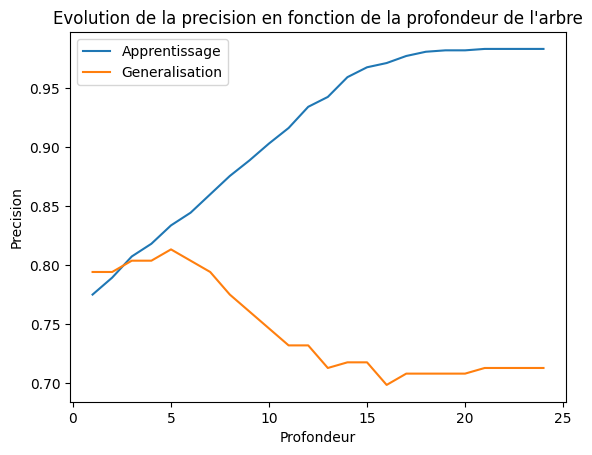

In [15]:
import matplotlib.pyplot as plt

train_percentage = 0.8
max_depth = 25

# Split data
train, test = [], []
for i in range(len(data)):
    if i < len(data) * train_percentage:
        train.append(data[i])
    else:
        test.append(data[i])

train_precision = []
test_precision = []
depths = range(1, max_depth)

for i in depths:
    racine = da.Noeud(profondeur_max=i)
    racine.grow(train)
    train_precision.append(da.precision(racine, train))
    test_precision.append(da.precision(racine, test))

plt.figure()
plt.title("Evolution de la precision en fonction de la profondeur de l'arbre")
plt.plot(depths, train_precision, label="Apprentissage")
plt.plot(depths, test_precision, label="Generalisation")
plt.xlabel("Profondeur")
plt.ylabel("Precision")
plt.legend()
plt.show()

Sur le graphique ci-dessus, on peut voir que la précision sur la base d'apprentissage est croissante avec la profondeur de l'arbre, et atteint son maximum pour une profondeur de 20 environ. En revanche, la précision sur la base de test atteint son maximum pour une profondeur de 5 environ, et décroit ensuite. Cela signifie très probablement qu'au delà de cette profondeur, l'arbre commence à surapprendre les données d'apprentissage, et n'est plus capable de généraliser correctement sur des données inconnues.

#### 14. Ajoutez une méthode `elagage` à la classe Noeud, prenant un coefficient $\alpha$, et à partir de la fin de l’arbre, retirant les noeuds jusqu’à trouver des noeuds ayant eu un gain d’entropie supérieur à $\alpha$.

In [16]:
racine = da.Noeud()
racine.grow(data)
print("La hauteur de l'arbre avant élagage est de {h}".format(h=racine.hauteur))
racine.elagage(0.01, data)
print("La hauteur de l'arbre après élagage est de {h}".format(h=racine.hauteur))

La hauteur de l'arbre avant élagage est de 24
La hauteur de l'arbre après élagage est de 20


#### 15. Tracez l’évolution de la précision sur la base d'apprentissage et la base de test en fonction de $\alpha$.

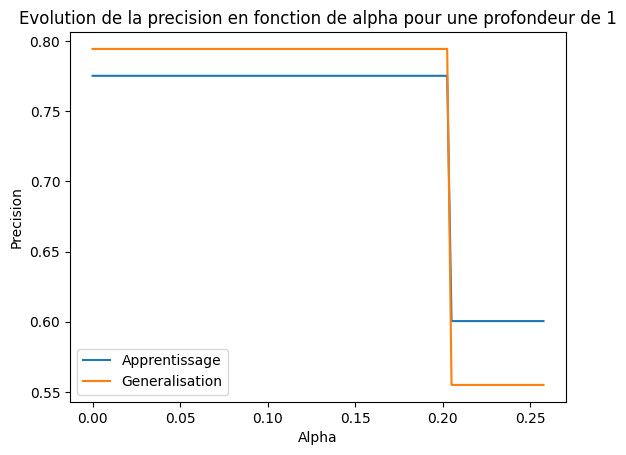

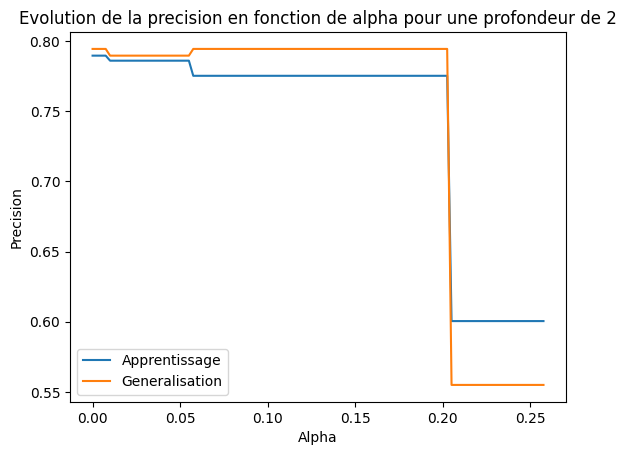

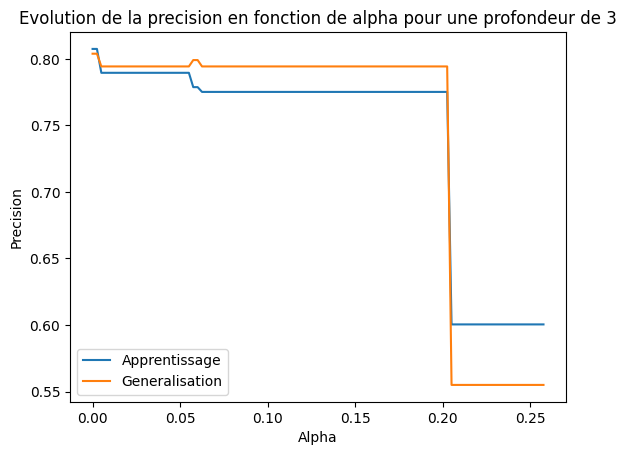

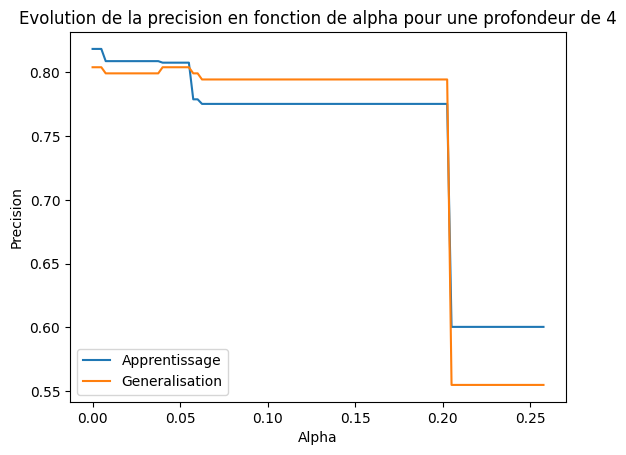

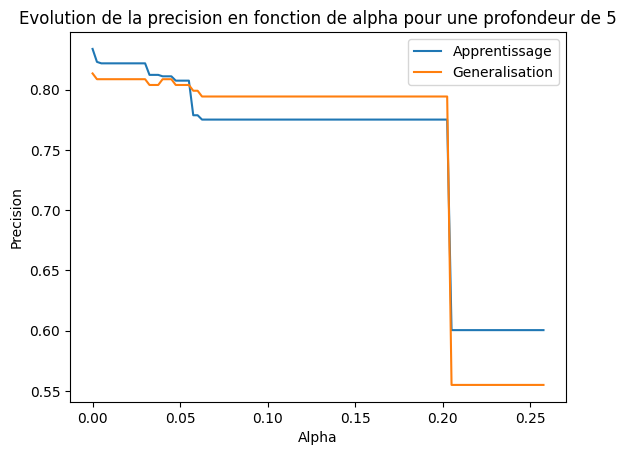

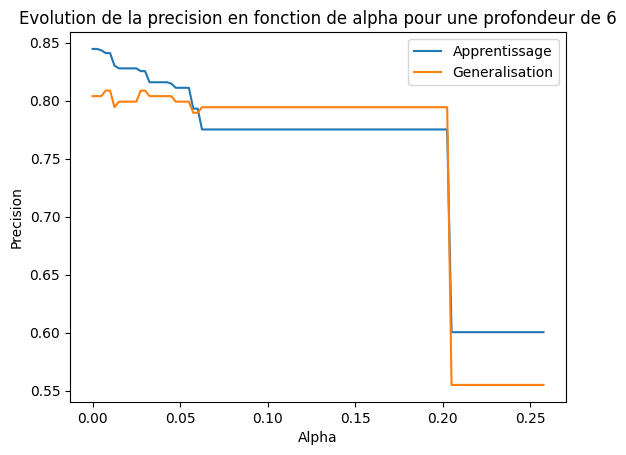

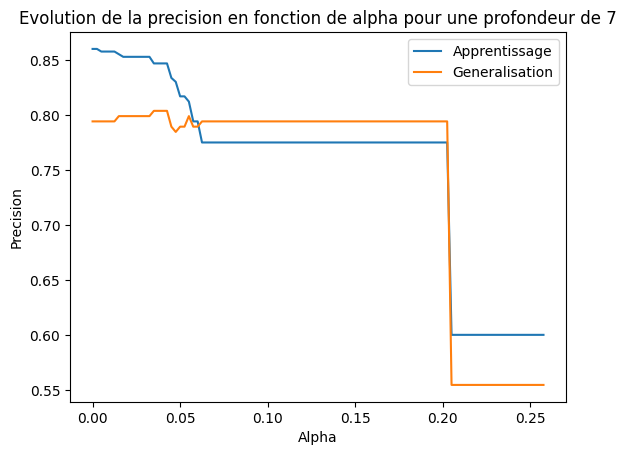

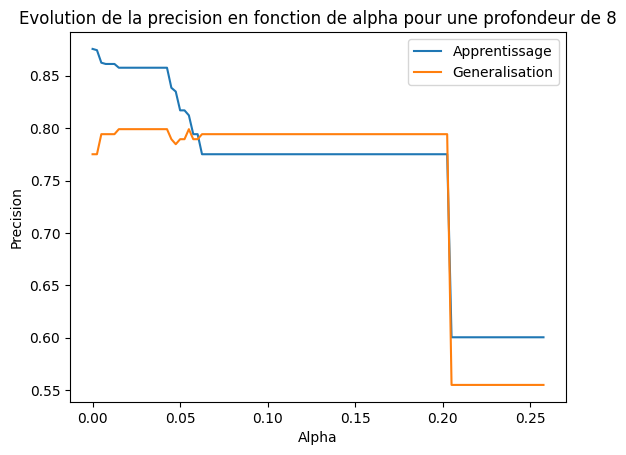

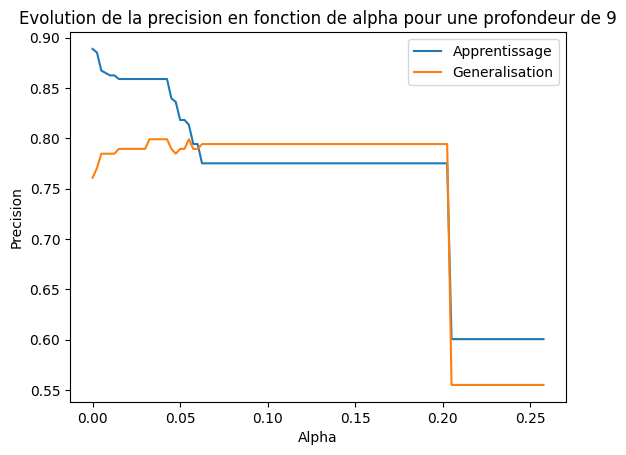

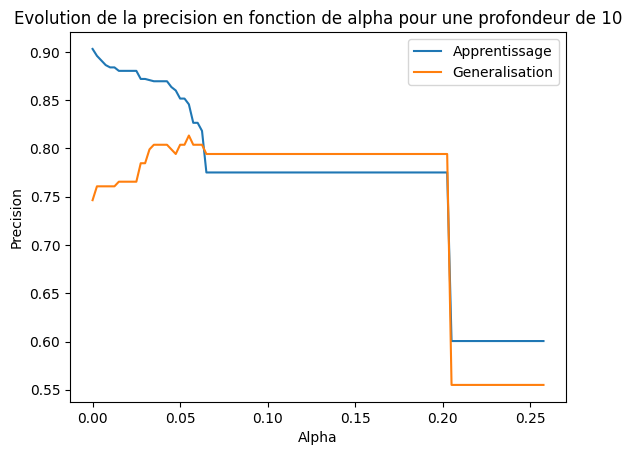

In [17]:
depths = range(1, 11)
alphas = [x/10000 for x in range(0, 2600, 25)]

for depths in depths:
    train_precision = []
    test_precision = []
    for alpha in alphas:
        racine = da.Noeud(profondeur_max=depths)
        racine.grow(train)
        racine.elagage(alpha, train)
        train_precision.append(da.precision(racine, train))
        test_precision.append(da.precision(racine, test))
    plt.figure()
    plt.title("Evolution de la precision en fonction de alpha pour une profondeur de {depth}".format(depth=depths))
    plt.plot(alphas, train_precision, label="Apprentissage")
    plt.plot(alphas, test_precision, label="Generalisation")
    plt.xlabel("Alpha")
    plt.ylabel("Precision")
    plt.legend()
    plt.show()


### Suite bonus : Forêts aléatoires

#### 16.  Créez une méthode `grow_partial` de classe Noeud

In [103]:
from numpy import sqrt

racine_r = da.Noeud()
k = round(sqrt(len(data[0].x)))
print("k = {k}".format(k=k))
racine_r.grow_partial(data, k)
print("La hauteur de l'arbre est de {h}".format(h=racine_r.hauteur))
print("La question utilisée par la racine est {key} < {value}".format(key=racine_r.question[0], value=racine_r.question[1]))
print("La precision de l'arbre est de {p}%".format(p=da.precision(racine_r, data)))

k = 3
La hauteur de l'arbre est de 22
La question utilisée par la racine est Nombre d enfants/parents a bord < 0.5
La precision de l'arbre est de 0.9435406698564593%


#### 17. Créez une classe ForetAleatoire, qui contiendra une liste de Noeuds

In [104]:
foret = da.ForetAleatoire(5)
foret.grow_simple(data, k)

for i in range(5):
    print("La hauteur de l'arbre {i} est de {h}".format(i=i, h=foret.foret[i].hauteur))
    print("La question utilisée par la racine est {key} < {value}".format(key=foret.foret[i].question[0], value=foret.foret[i].question[1]))

La hauteur de l'arbre 0 est de 23
La question utilisée par la racine est Genre < 0.5
La hauteur de l'arbre 1 est de 20
La question utilisée par la racine est Prix du ticket < 52.277100000000004
La hauteur de l'arbre 2 est de 19
La question utilisée par la racine est Prix du ticket < 52.277100000000004
La hauteur de l'arbre 3 est de 20
La question utilisée par la racine est Nombre d enfants/parents a bord < 0.5
La hauteur de l'arbre 4 est de 19
La question utilisée par la racine est Genre < 0.5


#### 18. Ajoutez une méthode `prediction` à la classe ForetAleatoire

In [105]:
x1, x2 = data[0].x, data[8].x
y1, y2 = data[0].y, data[8].y
c1 = foret.prediction(x1)
c2 = foret.prediction(x2)

print("La classe prédite de l'élément {x} est {classe}. La classe réelle est {real}".format(x=x1, classe=c1, real=y1))
print("La classe prédite de l'élément {x} est {classe}. La classe réelle est {real}".format(x=x2, classe=c2, real=y2))

La classe prédite de l'élément {'Classe': 3.0, 'Nationalite': 0.0, 'Age': 42.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 7.55, 'Genre': 0.0} est {0: 1.0}. La classe réelle est 0
La classe prédite de l'élément {'Classe': 3.0, 'Nationalite': 2.0, 'Age': 20.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 7.925, 'Genre': 0.0} est {1: 0.3619105691056911, 0: 0.6380894308943089}. La classe réelle est 1


#### 19. Créez une fonction `bootstrap`, prenant une liste de DataPoint *d* et un entier *n*, et renvoyant une liste de DataPoint comprenant *n* points, tirés de *d* par un tirage aléatoire uniforme avec remise.

In [106]:
bootstrap = da.bootstrap(data, 10)
print("La liste bootstrap contient {nb} éléments".format(nb=len(bootstrap)))
print("Le premier élément de la liste bootstrap est {x}".format(x=bootstrap[0]))

bootstrap = da.bootstrap(data, 10)
print("Le premier élément de la nouvelle liste bootstrap est {x}".format(x=bootstrap[0]))

La liste bootstrap contient 10 éléments
Le premier élément de la liste bootstrap est x: {'Classe': 3.0, 'Nationalite': 2.0, 'Age': 31.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 0.0, 'Prix du ticket': 8.6833, 'Genre': 1.0}, y: 1
Le premier élément de la nouvelle liste bootstrap est x: {'Classe': 1.0, 'Nationalite': 2.0, 'Age': 22.0, 'Nombre de freres/soeurs': 0.0, 'Nombre d enfants/parents a bord': 1.0, 'Prix du ticket': 61.9792, 'Genre': 1.0}, y: 1


#### 20. Equipez votre classe ForetAleatoire d’une méthode `grow`

In [107]:
foret = da.ForetAleatoire(10)
n = int((len(data)) / 2)
foret.grow(data, k, n)

#### 21. Faites grandir une ForetAleatoire sur votre base d’apprentissage, et tracez l’évolution de la précision sur la base d’apprentissage et la base de test en fonction du nombre d’arbres de la ForetAleatoire utilisés pour la prédiction.

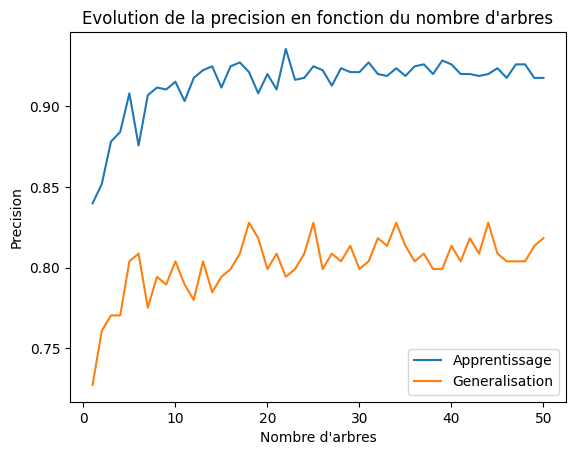

In [108]:
train_precision = []
test_precision = []
nb_arbres = range(1, 51)

for i in nb_arbres:
    foret = da.ForetAleatoire(i)
    foret.grow(train, k, n)
    train_precision.append(da.precision_foret(foret, train, "vote"))
    test_precision.append(da.precision_foret(foret, test, "vote"))

plt.figure()
plt.title("Evolution de la precision en fonction du nombre d'arbres")
plt.plot(nb_arbres, train_precision, label="Apprentissage")
plt.plot(nb_arbres, test_precision, label="Generalisation")
plt.xlabel("Nombre d'arbres")
plt.ylabel("Precision")
plt.legend()
plt.show()